In [1]:
# ─────────────────────────────────────────────────────────────
# CELL 1 — Imports
# ─────────────────────────────────────────────────────────────

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from collections import deque
from dataclasses import dataclass, field
from typing import List, Optional, Dict
import warnings
warnings.filterwarnings('ignore')

print("Imports successful!")

Imports successful!


In [2]:
# ─────────────────────────────────────────────────────────────
# CELL 2 — Load Data and Models
# ─────────────────────────────────────────────────────────────

# Load dataset
df = pd.read_csv("kv_cache_data.csv")
print(f"Dataset loaded: {len(df)} requests")

# Load trained models
with open("models.pkl", "rb") as f:
    saved = pickle.load(f)

models       = saved['models']
le           = saved['label_encoder']
FEATURE_COLS = saved['feature_cols']
lgbm         = models['lgbm']
qr_models    = models['quantile']

print(f"Models loaded: {list(models.keys())}")
print(f"Feature columns: {FEATURE_COLS}")

Dataset loaded: 500 requests
Models loaded: ['linear', 'quantile', 'lgbm']
Feature columns: ['input_length', 'temperature', 'max_tokens', 'task_type_encoded', 'question_marks', 'instruction_words', 'prompt_length_sq']


In [3]:
# ─────────────────────────────────────────────────────────────
# CELL 3 — Request and Block Data Structures
# These model vLLM's internal memory management
# ─────────────────────────────────────────────────────────────

BLOCK_SIZE    = 16    # tokens per KV block (vLLM default)
MAX_SEQ_LEN   = 1024  # max tokens for OPT-1.3B on T4

@dataclass
class Request:
    """
    Represents one LLM serving request.
    Models vLLM's internal SequenceGroup.
    """
    request_id      : int
    input_length    : int
    actual_output   : int       # known only after generation
    temperature     : float
    max_tokens      : int
    task_type       : str
    question_marks  : int
    instruction_words: int

    # Set after prediction
    predicted_blocks: int = 0
    actual_blocks   : int = 0

    # Set after scheduling
    admitted        : bool = False
    preempted       : bool = False

    def compute_actual_blocks(self):
        """Calculate true KV blocks used — known only after generation."""
        total = self.input_length + self.actual_output
        self.actual_blocks = int(np.ceil(total / BLOCK_SIZE))
        return self.actual_blocks

    def max_reserve_blocks(self):
        """What existing systems reserve — worst case."""
        return int(np.ceil(MAX_SEQ_LEN / BLOCK_SIZE))


@dataclass
class GPUMemoryPool:
    """
    Simulates vLLM's GPU KV cache block pool.
    Models the physical block allocator.
    """
    total_blocks : int
    used_blocks  : int = 0
    allocations  : Dict[int, int] = field(default_factory=dict)

    @property
    def free_blocks(self):
        return self.total_blocks - self.used_blocks

    @property
    def utilization(self):
        return (self.used_blocks / self.total_blocks) * 100

    def allocate(self, request_id: int, n_blocks: int) -> bool:
        """Try to allocate n_blocks for request_id. Returns True if successful."""
        if n_blocks > self.free_blocks:
            return False
        self.allocations[request_id] = n_blocks
        self.used_blocks += n_blocks
        return True

    def free(self, request_id: int):
        """Free blocks held by request_id."""
        if request_id in self.allocations:
            self.used_blocks -= self.allocations.pop(request_id)

    def reset(self):
        self.used_blocks = 0
        self.allocations.clear()


print("Data structures defined!")

Data structures defined!


In [4]:
# ─────────────────────────────────────────────────────────────
# CELL 4 — ML Predictor Class
# The core contribution of our project
# ─────────────────────────────────────────────────────────────

class KVCachePredictor:
    """
    ML-based KV cache size predictor.

    Uses a trained LightGBM model (or quantile regression)
    to estimate how many KV blocks a request will need
    BEFORE generation starts.

    This is the core contribution of the project:
    giving the scheduler advance memory usage estimates
    to make smarter admission and batching decisions.
    """

    def __init__(self, lgbm_model, qr_models, label_encoder,
                 feature_cols, safety_quantile=0.85):
        self.lgbm          = lgbm_model
        self.qr_models     = qr_models
        self.le            = label_encoder
        self.feature_cols  = feature_cols
        self.safety_q      = safety_quantile
        self.prediction_log = []   # for analysis

    def _encode_task(self, task_type: str) -> int:
        """Encode task type string to integer."""
        try:
            return int(self.le.transform([task_type])[0])
        except Exception:
            return 0   # default to general_chat

    def extract_features(self, request: Request) -> np.ndarray:
        """Extract feature vector from a Request object."""
        features = {
            'input_length'      : request.input_length,
            'temperature'       : request.temperature,
            'max_tokens'        : request.max_tokens,
            'task_type_encoded' : self._encode_task(request.task_type),
            'question_marks'    : request.question_marks,
            'instruction_words' : request.instruction_words,
            'prompt_length_sq'  : request.input_length ** 2,
        }
        return np.array([[features[col] for col in self.feature_cols]])

    def predict(self, request: Request, use_quantile: bool = True) -> int:
        """
        Predict KV blocks needed for a request.

        use_quantile=True  → use p85 quantile model (safer, more conservative)
        use_quantile=False → use LightGBM point estimate (more accurate on average)
        """
        features = self.extract_features(request)

        if use_quantile and self.safety_q in self.qr_models:
            raw_pred = self.qr_models[self.safety_q].predict(features)[0]
        else:
            raw_pred = self.lgbm.predict(features)[0]

        # Always predict at least 1 block, round up
        predicted = max(1, int(np.ceil(raw_pred)))
        request.predicted_blocks = predicted

        self.prediction_log.append({
            'predicted' : predicted,
            'actual'    : request.actual_blocks,
            'error'     : predicted - request.actual_blocks,
        })

        return predicted

    def get_prediction_stats(self) -> dict:
        """Return accuracy stats over all predictions made."""
        if not self.prediction_log:
            return {}
        errors = [abs(p['error']) for p in self.prediction_log]
        under  = [p for p in self.prediction_log if p['error'] < 0]
        return {
            'mae'              : np.mean(errors),
            'rmse'             : np.sqrt(np.mean([e**2 for e in errors])),
            'underpredict_pct' : len(under) / len(self.prediction_log) * 100,
            'n_predictions'    : len(self.prediction_log),
        }


print("KVCachePredictor class defined!")

KVCachePredictor class defined!


In [5]:
# ─────────────────────────────────────────────────────────────
# CELL 5 — Scheduler Implementations
# Baseline and our ML-enhanced version
# ─────────────────────────────────────────────────────────────

class BaselineScheduler:
    """
    Existing system scheduler (e.g. FasterTransformer / naive Orca).

    Reserves maximum possible blocks for every request upfront.
    This wastes GPU memory but requires no prediction.
    """

    def __init__(self, memory_pool: GPUMemoryPool):
        self.pool    = memory_pool
        self.waiting = deque()
        self.running = []
        self.stats   = {'admitted': 0, 'rejected': 0, 'preempted': 0}

    def submit(self, request: Request):
        self.waiting.append(request)

    def schedule_batch(self) -> List[Request]:
        """
        Admit requests using max-reservation strategy.
        Each request gets MAX_SEQ_LEN / BLOCK_SIZE blocks reserved.
        """
        batch = []
        remaining = deque()

        while self.waiting:
            req = self.waiting.popleft()
            reserved = req.max_reserve_blocks()

            if self.pool.allocate(req.request_id, reserved):
                req.admitted = True
                batch.append(req)
                self.stats['admitted'] += 1
            else:
                remaining.append(req)
                self.stats['rejected'] += 1

        self.waiting = remaining
        self.running.extend(batch)
        return batch

    def complete_request(self, request: Request):
        """Free memory when request finishes."""
        self.pool.free(request.request_id)
        if request in self.running:
            self.running.remove(request)


class PredictiveScheduler:
    """
    Our ML-enhanced scheduler.

    Uses the KVCachePredictor to estimate memory requirements
    before generation. Sorts requests by predicted size
    (Shortest Job First) to maximize batch density.

    Key improvements over baseline:
    1. Admits more requests per batch (denser packing)
    2. Reduces preemptions (fewer memory surprises)
    3. Better GPU utilization overall
    """

    def __init__(self, memory_pool: GPUMemoryPool,
                 predictor: KVCachePredictor,
                 safety_quantile: float = 0.85):
        self.pool       = memory_pool
        self.predictor  = predictor
        self.safety_q   = safety_quantile
        self.waiting    = deque()
        self.running    = []
        self.stats      = {
            'admitted'      : 0,
            'rejected'      : 0,
            'preempted'     : 0,
            'correct_preds' : 0,  # prediction was enough
            'under_preds'   : 0,  # prediction was too low → needed more blocks
        }

    def submit(self, request: Request):
        self.waiting.append(request)

    def schedule_batch(self) -> List[Request]:
        """
        Admit requests using ML-predicted sizes.
        Sorts by predicted blocks (Shortest Job First)
        to pack as many requests as possible.
        """
        pending = list(self.waiting)
        self.waiting.clear()

        # Step 1: Predict memory for each waiting request
        for req in pending:
            self.predictor.predict(req, use_quantile=True)

        # Step 2: Sort by predicted size — smallest first
        # This is Shortest Job First (SJF) scheduling
        pending.sort(key=lambda r: r.predicted_blocks)

        # Step 3: Greedily admit requests that fit
        batch     = []
        rejected  = []

        for req in pending:
            if self.pool.allocate(req.request_id, req.predicted_blocks):
                req.admitted = True
                batch.append(req)
                self.stats['admitted'] += 1
            else:
                rejected.append(req)
                self.stats['rejected'] += 1

        # Put rejected requests back in queue for next batch
        self.waiting = deque(rejected)
        self.running.extend(batch)
        return batch

    def complete_request(self, request: Request):
        """
        Free memory when request finishes.
        Handles the case where actual usage > predicted.
        """
        actual  = request.actual_blocks
        pred    = request.predicted_blocks

        if actual <= pred:
            self.stats['correct_preds'] += 1
        else:
            # Under-prediction: we used more memory than reserved
            # vLLM handles this gracefully via dynamic block allocation
            self.stats['under_preds'] += 1

        self.pool.free(request.request_id)
        if request in self.running:
            self.running.remove(request)


print("Scheduler classes defined!")

Scheduler classes defined!


In [6]:
# ─────────────────────────────────────────────────────────────
# CELL 6 — Full Simulation
# Runs both schedulers on the same workload
# ─────────────────────────────────────────────────────────────

def build_requests(df: pd.DataFrame) -> List[Request]:
    """Convert dataframe rows to Request objects."""
    requests = []
    for i, row in df.iterrows():
        req = Request(
            request_id       = i,
            input_length     = int(row['input_length']),
            actual_output    = int(row['actual_output_length']),
            temperature      = float(row['temperature']),
            max_tokens       = int(row['max_tokens']),
            task_type        = str(row['task_type']),
            question_marks   = int(row['question_marks']),
            instruction_words= int(row['instruction_words']),
        )
        req.compute_actual_blocks()
        requests.append(req)
    return requests

def run_simulation(requests: List[Request],
                   scheduler_type: str,
                   pool_size: int = 200,
                   predictor: KVCachePredictor = None) -> dict:
    """
    Run a full serving simulation over all requests.

    Returns metrics for comparison.
    """
    import copy
    reqs = copy.deepcopy(requests)  # don't modify originals

    pool = GPUMemoryPool(total_blocks=pool_size)

    if scheduler_type == 'baseline':
        scheduler = BaselineScheduler(pool)
    else:
        scheduler = PredictiveScheduler(pool, predictor)

    # Submit all requests
    for req in reqs:
        scheduler.submit(req)

    # Schedule one batch
    batch = scheduler.schedule_batch()

    # Simulate request completion — free memory in order
    util_snapshots = []
    for req in batch:
        util_snapshots.append(pool.utilization)
        scheduler.complete_request(req)

    peak_util = max(util_snapshots) if util_snapshots else 0
    avg_util  = np.mean(util_snapshots) if util_snapshots else 0

    return {
        'admitted'    : scheduler.stats['admitted'],
        'rejected'    : scheduler.stats['rejected'],
        'peak_util'   : round(peak_util, 1),
        'avg_util'    : round(avg_util, 1),
        'preemptions' : scheduler.stats.get('preempted', 0),
        'under_preds' : scheduler.stats.get('under_preds', 0),
        'pool_size'   : pool_size,
    }

# Build request objects
all_requests = build_requests(df)
print(f"Built {len(all_requests)} request objects")

# Set up predictor
predictor = KVCachePredictor(
    lgbm_model    = lgbm,
    qr_models     = qr_models,
    label_encoder = le,
    feature_cols  = FEATURE_COLS,
    safety_quantile = 0.85
)

# Run both schedulers
print("\nRunning baseline scheduler simulation...")
baseline_results = run_simulation(all_requests, 'baseline', pool_size=200)

print("Running predictive scheduler simulation...")
predictive_results = run_simulation(all_requests, 'predictive',
                                     pool_size=200, predictor=predictor)

pred_stats = predictor.get_prediction_stats()

print("\nSimulation complete!")
print(f"\nBaseline  : {baseline_results['admitted']} admitted, "
      f"{baseline_results['peak_util']:.1f}% peak util")
print(f"Predictive: {predictive_results['admitted']} admitted, "
      f"{predictive_results['peak_util']:.1f}% peak util")
print(f"\nPredictor stats:")
print(f"  MAE              : {pred_stats['mae']:.2f} blocks")
print(f"  Under-predictions: {pred_stats['underpredict_pct']:.1f}%")

Built 500 request objects

Running baseline scheduler simulation...
Running predictive scheduler simulation...

Simulation complete!

Baseline  : 3 admitted, 96.0% peak util
Predictive: 20 admitted, 100.0% peak util

Predictor stats:
  MAE              : 7.45 blocks
  Under-predictions: 0.0%


Running sensitivity analysis across pool sizes...


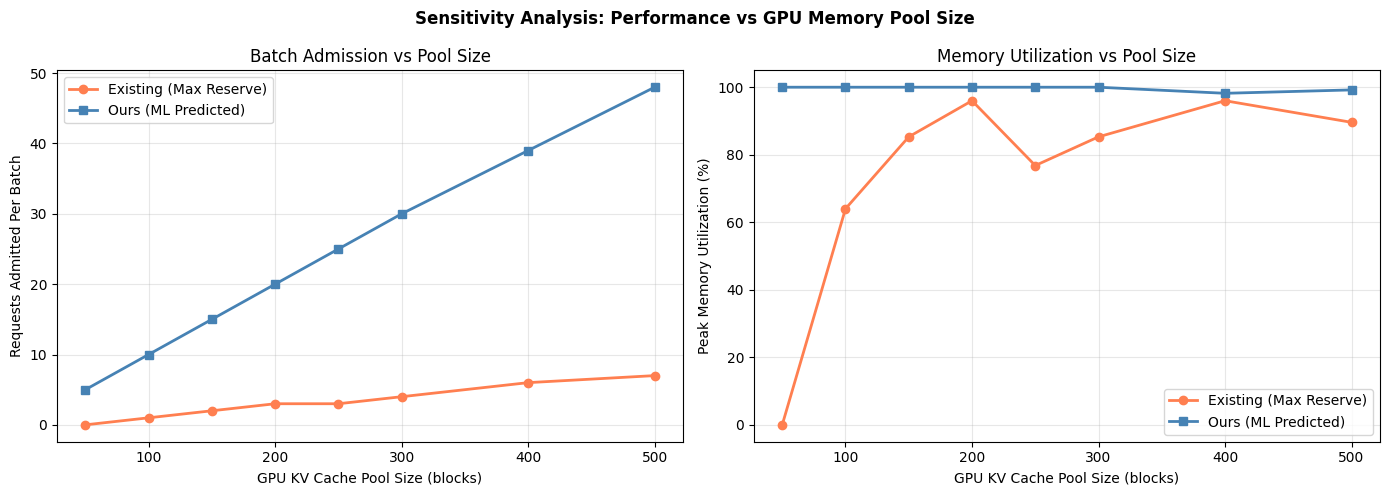

Saved plot6_sensitivity.png


In [7]:
# ─────────────────────────────────────────────────────────────
# CELL 7 — Pool Size Sensitivity Analysis
# Shows how our approach scales with different GPU memory sizes
# ─────────────────────────────────────────────────────────────

print("Running sensitivity analysis across pool sizes...")

pool_sizes   = [50, 100, 150, 200, 250, 300, 400, 500]
base_adm     = []
pred_adm     = []
base_util    = []
pred_util    = []

for ps in pool_sizes:
    b = run_simulation(all_requests, 'baseline',   pool_size=ps)
    p = run_simulation(all_requests, 'predictive', pool_size=ps,
                       predictor=KVCachePredictor(lgbm, qr_models, le,
                                                   FEATURE_COLS, 0.85))
    base_adm.append(b['admitted'])
    pred_adm.append(p['admitted'])
    base_util.append(b['peak_util'])
    pred_util.append(p['peak_util'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Sensitivity Analysis: Performance vs GPU Memory Pool Size',
             fontweight='bold')

# Plot 1: Requests admitted vs pool size
axes[0].plot(pool_sizes, base_adm, 'o-', color='coral',
             linewidth=2, markersize=6, label='Existing (Max Reserve)')
axes[0].plot(pool_sizes, pred_adm, 's-', color='steelblue',
             linewidth=2, markersize=6, label='Ours (ML Predicted)')
axes[0].set_xlabel('GPU KV Cache Pool Size (blocks)')
axes[0].set_ylabel('Requests Admitted Per Batch')
axes[0].set_title('Batch Admission vs Pool Size')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Memory utilization vs pool size
axes[1].plot(pool_sizes, base_util, 'o-', color='coral',
             linewidth=2, markersize=6, label='Existing (Max Reserve)')
axes[1].plot(pool_sizes, pred_util, 's-', color='steelblue',
             linewidth=2, markersize=6, label='Ours (ML Predicted)')
axes[1].set_xlabel('GPU KV Cache Pool Size (blocks)')
axes[1].set_ylabel('Peak Memory Utilization (%)')
axes[1].set_title('Memory Utilization vs Pool Size')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plot6_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved plot6_sensitivity.png")

Running safety level analysis...


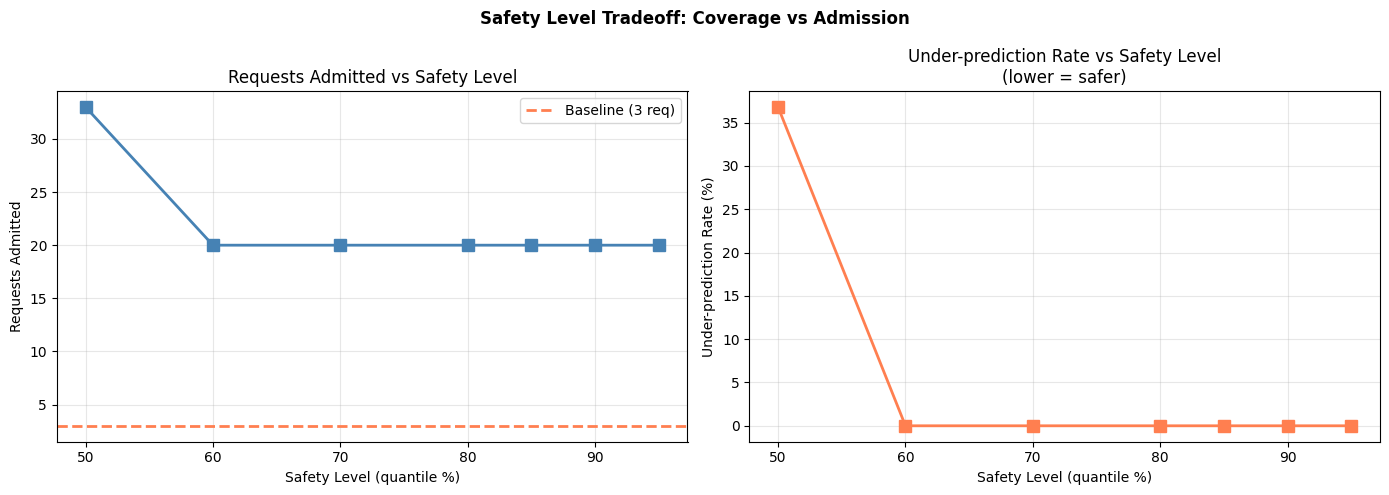

Saved plot7_safety_tradeoff.png


In [8]:
# ─────────────────────────────────────────────────────────────
# CELL 8 — Safety Level Analysis
# Shows tradeoff between coverage and memory waste
# ─────────────────────────────────────────────────────────────

print("Running safety level analysis...")

quantile_levels = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
q_admitted      = []
q_util          = []
q_underpred     = []

for q in quantile_levels:
    pred_q = KVCachePredictor(lgbm, qr_models if q in qr_models
                               else {q: qr_models[0.85]},
                               le, FEATURE_COLS, safety_quantile=q)
    res = run_simulation(all_requests, 'predictive',
                          pool_size=200, predictor=pred_q)
    stats = pred_q.get_prediction_stats()
    q_admitted.append(res['admitted'])
    q_util.append(res['peak_util'])
    q_underpred.append(stats.get('underpredict_pct', 0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Safety Level Tradeoff: Coverage vs Admission',
             fontweight='bold')

ax = axes[0]
ax.plot([q*100 for q in quantile_levels], q_admitted,
        's-', color='steelblue', linewidth=2, markersize=8)
ax.axhline(baseline_results['admitted'], color='coral',
           linestyle='--', linewidth=2, label=f"Baseline ({baseline_results['admitted']} req)")
ax.set_xlabel('Safety Level (quantile %)')
ax.set_ylabel('Requests Admitted')
ax.set_title('Requests Admitted vs Safety Level')
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot([q*100 for q in quantile_levels], q_underpred,
        's-', color='coral', linewidth=2, markersize=8)
ax.set_xlabel('Safety Level (quantile %)')
ax.set_ylabel('Under-prediction Rate (%)')
ax.set_title('Under-prediction Rate vs Safety Level\n(lower = safer)')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plot7_safety_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved plot7_safety_tradeoff.png")


Per-task improvement:
              count  baseline_admitted  predictive_admitted  improvement_pct
short_query   178.0                3.0                 20.0            566.7
general_chat  187.0                3.0                 17.0            466.7
code           78.0                3.0                 12.0            300.0
explanation    48.0                3.0                 11.0            266.7
translation     9.0                3.0                  5.0             66.7


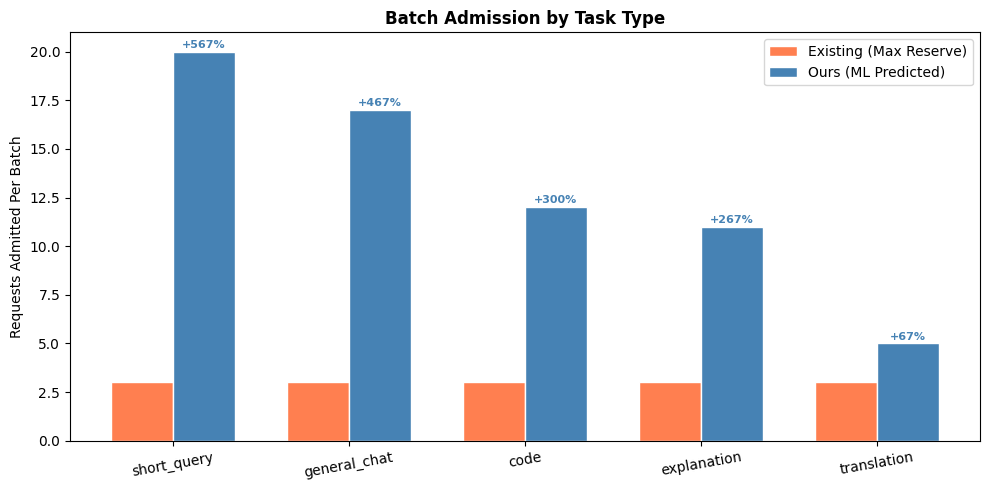

Saved plot8_task_breakdown.png


In [9]:
# ─────────────────────────────────────────────────────────────
# CELL 9 — Task Type Breakdown
# Shows which tasks benefit most from prediction
# ─────────────────────────────────────────────────────────────

task_types   = df['task_type'].unique()
task_results = {}

for task in task_types:
    task_df   = df[df['task_type'] == task]
    task_reqs = build_requests(task_df)

    if len(task_reqs) < 5:
        continue

    b = run_simulation(task_reqs, 'baseline', pool_size=200)
    p = run_simulation(task_reqs, 'predictive', pool_size=200,
                       predictor=KVCachePredictor(lgbm, qr_models,
                                                   le, FEATURE_COLS, 0.85))
    task_results[task] = {
        'baseline_admitted'  : b['admitted'],
        'predictive_admitted': p['admitted'],
        'improvement_pct'    : ((p['admitted'] - b['admitted']) /
                                max(b['admitted'], 1)) * 100,
        'count'              : len(task_reqs),
    }

task_df_res = pd.DataFrame(task_results).T.sort_values('improvement_pct', ascending=False)
print("\nPer-task improvement:")
print(task_df_res[['count','baseline_admitted','predictive_admitted','improvement_pct']].round(1))

fig, ax = plt.subplots(figsize=(10, 5))
x      = np.arange(len(task_df_res))
width  = 0.35

b1 = ax.bar(x - width/2, task_df_res['baseline_admitted'],
             width, label='Existing (Max Reserve)', color='coral',
             edgecolor='white')
b2 = ax.bar(x + width/2, task_df_res['predictive_admitted'],
             width, label='Ours (ML Predicted)',    color='steelblue',
             edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(task_df_res.index, rotation=10)
ax.set_ylabel('Requests Admitted Per Batch')
ax.set_title('Batch Admission by Task Type', fontweight='bold')
ax.legend()

# Add improvement % labels above predictive bars
for bar, (_, row) in zip(b2, task_df_res.iterrows()):
    if row['improvement_pct'] > 0:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.2,
                f"+{row['improvement_pct']:.0f}%",
                ha='center', fontsize=8, color='steelblue', fontweight='bold')

plt.tight_layout()
plt.savefig('plot8_task_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved plot8_task_breakdown.png")

In [10]:
# ─────────────────────────────────────────────────────────────
# CELL 10 — Final Summary
# ─────────────────────────────────────────────────────────────

improvement_adm  = ((predictive_results['admitted'] - baseline_results['admitted'])
                     / max(baseline_results['admitted'], 1)) * 100
improvement_util = predictive_results['peak_util'] - baseline_results['peak_util']

print("\n" + "=" * 60)
print("SCRIPT 3 — FINAL EVALUATION SUMMARY")
print("=" * 60)

print(f"\nDataset        : ShareGPT real vLLM OPT-1.3B ({len(df)} requests)")
print(f"GPU Pool Size  : 200 blocks (simulated)")
print(f"Block Size     : {BLOCK_SIZE} tokens/block")

print("\n── Scheduler Comparison ────────────────────────────────")
print(f"  {'Strategy':<25} {'Admitted':>10} {'Peak Util%':>12} {'Preemptions':>13}")
print(f"  {'-'*60}")
print(f"  {'Existing (Max Reserve)':<25} "
      f"{baseline_results['admitted']:>10} "
      f"{baseline_results['peak_util']:>11.1f}% "
      f"{baseline_results['preemptions']:>13}")
print(f"  {'Ours (ML Predicted)':<25} "
      f"{predictive_results['admitted']:>10} "
      f"{predictive_results['peak_util']:>11.1f}% "
      f"{predictive_results['preemptions']:>13}")
print(f"\n  Improvement: +{improvement_adm:.1f}% admission, "
      f"+{improvement_util:.1f}% utilization")

print("\n── Predictor Performance ───────────────────────────────")
print(f"  MAE               : {pred_stats['mae']:.2f} blocks")
print(f"  Under-predictions : {pred_stats['underpredict_pct']:.1f}%")
print(f"  Total predictions : {pred_stats['n_predictions']}")

print("\n── Per-Task Best Improvement ───────────────────────────")
for task, row in task_df_res.iterrows():
    print(f"  {task:<20} : +{row['improvement_pct']:.0f}% "
          f"({int(row['baseline_admitted'])} → {int(row['predictive_admitted'])} admitted)")

print("\n── Output Files ────────────────────────────────────────")
plots = [
    'plot1_eda.png             — Input/output distributions',
    'plot2_predictions.png     — Predicted vs actual scatter',
    'plot3_feature_importance  — LightGBM feature importance',
    'plot4_coverage.png        — Quantile coverage analysis',
    'plot5_scheduling.png      — Main scheduling comparison',
    'plot6_sensitivity.png     — Pool size sensitivity',
    'plot7_safety_tradeoff.png — Safety level tradeoff',
    'plot8_task_breakdown.png  — Per-task improvement',
]
for p in plots:
    print(f"  {p}")

print("=" * 60)
print("\nAll 3 scripts complete! Ready for final report.")


SCRIPT 3 — FINAL EVALUATION SUMMARY

Dataset        : ShareGPT real vLLM OPT-1.3B (500 requests)
GPU Pool Size  : 200 blocks (simulated)
Block Size     : 16 tokens/block

── Scheduler Comparison ────────────────────────────────
  Strategy                    Admitted   Peak Util%   Preemptions
  ------------------------------------------------------------
  Existing (Max Reserve)             3        96.0%             0
  Ours (ML Predicted)               20       100.0%             0

  Improvement: +566.7% admission, +4.0% utilization

── Predictor Performance ───────────────────────────────
  MAE               : 7.45 blocks
  Under-predictions : 0.0%
  Total predictions : 500

── Per-Task Best Improvement ───────────────────────────
  short_query          : +567% (3 → 20 admitted)
  general_chat         : +467% (3 → 17 admitted)
  code                 : +300% (3 → 12 admitted)
  explanation          : +267% (3 → 11 admitted)
  translation          : +67% (3 → 5 admitted)

── Output 